In [92]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

import warnings
warnings.filterwarnings("ignore")

In [93]:
df = pd.read_csv("student-dataset.csv")

print("Dataset Loaded Successfully")

Dataset Loaded Successfully


In [94]:
print("Dataset Display")
df.head()
df.tail()
df.info()
df.describe()
print(df.shape)
print(df.columns)

Dataset Display
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307 entries, 0 to 306
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  307 non-null    int64  
 1   name                307 non-null    object 
 2   nationality         307 non-null    object 
 3   city                307 non-null    object 
 4   latitude            307 non-null    float64
 5   longitude           307 non-null    float64
 6   gender              307 non-null    object 
 7   ethnic.group        0 non-null      float64
 8   age                 307 non-null    int64  
 9   english.grade       307 non-null    float64
 10  math.grade          307 non-null    float64
 11  sciences.grade      307 non-null    float64
 12  language.grade      307 non-null    float64
 13  portfolio.rating    307 non-null    int64  
 14  coverletter.rating  307 non-null    float64
 15  refletter.rating    307 non-null    int64

In [95]:
print("Data Cleaning")
print(df.isnull().sum())
df.fillna(df.mean(numeric_only=True), inplace=True)

print("Missing Values Filled")

print(df.duplicated().sum())

df.drop_duplicates(inplace=True)

print("Duplicate Records Removed")

Data Cleaning
id                      0
name                    0
nationality             0
city                    0
latitude                0
longitude               0
gender                  0
ethnic.group          307
age                     0
english.grade           0
math.grade              0
sciences.grade          0
language.grade          0
portfolio.rating        0
coverletter.rating      0
refletter.rating        0
dtype: int64
Missing Values Filled
0
Duplicate Records Removed


## Feature Selection

In [96]:
X = df[[
    "age",
    "english.grade",
    "sciences.grade",
    "language.grade",
    "portfolio.rating",
    "coverletter.rating",
    "refletter.rating"
]]

y = df["math.grade"]

In [97]:
X.head()

,age,english.grade,sciences.grade,language.grade,portfolio.rating,coverletter.rating,refletter.rating
0,22,3.5,3.1,1.0,4,4.0,4
1,22,2.9,3.6,5.0,5,4.0,5
2,22,3.9,3.2,5.0,3,3.0,4
3,20,3.3,3.2,5.0,5,2.0,4
4,21,3.7,3.4,1.0,4,4.0,5


## Train Test Split

In [98]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

## Linear Regression Model

In [99]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Model Trained Successfully")

Model Trained Successfully


In [100]:
y_pred = model.predict(X_test)

## Model Coefficients

In [101]:
print("Intercept :", model.intercept_)

print()

print("Coefficients :")

for feature, coef in zip(X.columns, model.coef_):
    print(feature, ":", coef)

Intercept : 2.40646021790917

Coefficients :
age : 0.016823580841195476
english.grade : -0.008763640139037993
sciences.grade : 0.09752283828678418
language.grade : -0.01645280446727593
portfolio.rating : 0.06768293115788446
coverletter.rating : 0.046499496689738795
refletter.rating : -0.009064886216247646


## Scatter Plot

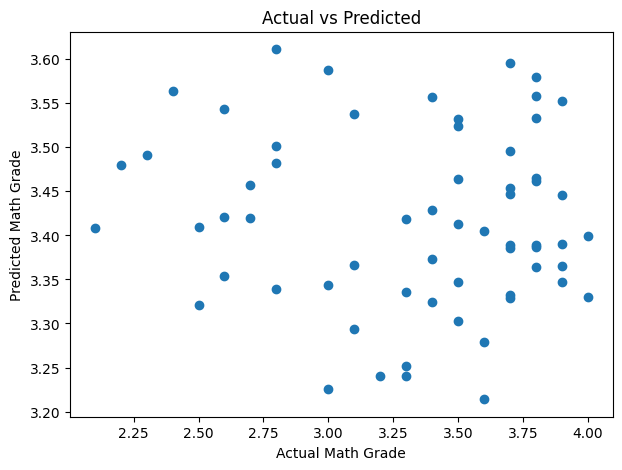

In [102]:
plt.figure(figsize=(7,5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Math Grade")

plt.ylabel("Predicted Math Grade")

plt.title("Actual vs Predicted")

plt.show()

## Regression Line

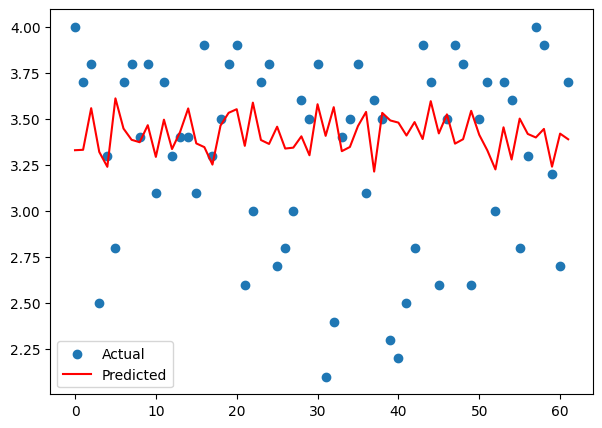

In [103]:
plt.figure(figsize=(7,5))

plt.scatter(range(len(y_test)), y_test, label="Actual")

plt.plot(range(len(y_pred)), y_pred, color="red", label="Predicted")

plt.legend()

plt.show()

## Evaluation Metrics

In [104]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error :", mae)

print("Mean Squared Error :", mse)

print("Root Mean Squared Error :", rmse)

print("R2 Score :", r2)

Mean Absolute Error : 0.4191116242667729
Mean Squared Error : 0.28315187088577504
Root Mean Squared Error : 0.5321201658326576
R2 Score : -0.10353211096289172


## Prediction Table

In [105]:
result = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})

result.head(15)

,Actual,Predicted
183,4.0,3.329970
60,3.7,3.332142
124,3.8,3.558193
93,2.5,3.320544
63,3.3,3.239803
9,2.8,3.611427
147,3.7,3.447365
158,3.8,3.386433
168,3.4,3.373339
33,3.8,3.465747


## Manual 2x2 Confusion Matrix

Linear regression predicts continuous grades, so this is a supplementary classification-style view. Here, grades of 3.0 or above are positive and grades below 3.0 are negative. Interpret accuracy cautiously: the model predicts every test record as positive at this cutoff.

Accuracy: 75.81%


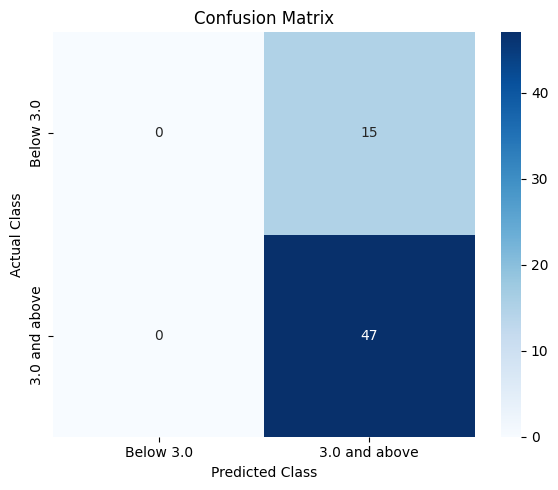

In [106]:
threshold = 3.0

actual_positive = y_test.to_numpy() >= threshold
predicted_positive = y_pred >= threshold

true_negative = np.sum(~actual_positive & ~predicted_positive)
false_positive = np.sum(~actual_positive & predicted_positive)
false_negative = np.sum(actual_positive & ~predicted_positive)
true_positive = np.sum(actual_positive & predicted_positive)
accuracy = (true_positive + true_negative) / len(y_test)
print(f"Accuracy: {accuracy:.2%}")

confusion_matrix_manual = np.array([
    [true_negative, false_positive],
    [false_negative, true_positive]
])

class_labels = ["Below 3.0", "3.0 and above"]
plt.figure(figsize=(6, 5))
sns.heatmap(
    confusion_matrix_manual,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_labels,
    yticklabels=class_labels
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()
